In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})


df.loc[0, 'Income'] = 5_000_000


churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)

   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int64
Income         float64
Tenure           int64
CreditScore      int64
Gender          object
Education       object
City            object
Churn            int64
dtype: object


## Часть 1. Аналитика: постановка задачи

### Задание 1.1. SMART-формулировка

Бизнес ставит задачу так: «хотим снизить отток клиентов». Это не является постановкой задачи — в ней нет метрики, сегмента, срока и способа проверки.

Переформулируйте задачу в SMART-формате по шаблону:

> Снизить \<метрика> на \<X %> в сегменте \<сегмент> за \<срок> за счёт \<действие>.

Запишите формулировку в ячейку и распишите каждый элемент SMART.

```python
smart_goal = "..."
# Распишите каждый элемент

In [4]:
smart_goal = "Снизить долю оттока клиентов (churn) с 37% до 32% в сегменте возраста от 50 до 60 лет за полгода за счёт льготных предложений."

# s - : метрика churn и сегмент от 50 до 60
# m - : c 37 до 32 конкретные цифры
# a - : снижение на 5 п.п. за счёт льгот
# r - : снижение оттока напрямую влияет на прибыль банка.
# t - : полгода.

print(smart_goal)

Снизить долю оттока клиентов (churn) с 37% до 32% в сегменте возраста от 50 до 60 лет за полгода за счёт льготных предложений.


### Задание 1.2. Декомпозиция «Почему клиенты уходят»

Постройте MECE-дерево глубины 2–3 уровня. Каждый лист дерева должен соответствовать метрике, которую можно посчитать на текущем датасете. Дерево оформите в виде вложенного словаря Python и напишите функцию обхода.

Минимальный набор веток верхнего уровня:

- число активных клиентов (новые и уходящие существующие);
- доход, приносимый клиентом (на клиента, частота операций);
- качество обслуживания (обращения в поддержку, скорость ответа).

Листья заполните сами — например, `churn_rate`, `avg_income_per_client`, `avg_tenure_of_churned`.

In [5]:
decomposition_tree = {
    "1. Число активных клиентов": {
        "1.1. Новые клиенты": {
            "new_clients_count": "Количество новых регистраций в системе"
        },
        "1.2. Уходящие существующие клиенты": {
            "churn_rate": "Доля ушедших клиентов от всей базы",
            "avg_tenure_of_churned": "Средний стаж ушедших клиентов (по столбцу Tenure для Churn==1)"
        }
    },
    "2. Доход, приносимый клиентом": {
        "2.1. Доход на клиента": {
            "avg_income_per_client": "Средний доход клиента по базе (по столбцу Income)",
            "target_segment_avg_income": "Средний доход клиентов в целевом сегменте 50-60 лет"
        },
        "2.2. Частота операций": {
            "avg_transaction_frequency": "Среднее количество транзакций клиента за месяц"
        }
    },
    "3. Качество обслуживания": {
        "3.1. Обращения в поддержку": {
            "support_tickets_count": "Общее количество заявок в службу поддержки"
        },
        "3.2. Скорость ответа": {
            "avg_response_time": "Среднее время ответа оператора на обращение"
        }
    }
}


def print_tree(tree, level=0):
    for key, value in tree.items():
        print("    " * level + f"└── {key}")
        if isinstance(value, dict):
            print_tree(value, level + 1)
        else:
            print("    " * (level + 1) + f" [Метрика: {value}]")


print_tree(decomposition_tree)


└── 1. Число активных клиентов
    └── 1.1. Новые клиенты
        └── new_clients_count
             [Метрика: Количество новых регистраций в системе]
    └── 1.2. Уходящие существующие клиенты
        └── churn_rate
             [Метрика: Доля ушедших клиентов от всей базы]
        └── avg_tenure_of_churned
             [Метрика: Средний стаж ушедших клиентов (по столбцу Tenure для Churn==1)]
└── 2. Доход, приносимый клиентом
    └── 2.1. Доход на клиента
        └── avg_income_per_client
             [Метрика: Средний доход клиента по базе (по столбцу Income)]
        └── target_segment_avg_income
             [Метрика: Средний доход клиентов в целевом сегменте 50-60 лет]
    └── 2.2. Частота операций
        └── avg_transaction_frequency
             [Метрика: Среднее количество транзакций клиента за месяц]
└── 3. Качество обслуживания
    └── 3.1. Обращения в поддержку
        └── support_tickets_count
             [Метрика: Общее количество заявок в службу поддержки]
    └── 3.2. 

### Задание 1.3. Типы смещений выборки

Для каждого сценария укажите тип систематического смещения: `selection`, `survivorship`, `response`, `recall`.

1. Аналитик изучает успешные стартапы, чтобы вывести формулу успеха.
2. Опрос «довольны ли вы сервисом?» проводится на сайте банка.
3. Модель обучали на клиентах, пришедших через рекламу Google.
4. Пользователей спрашивают «сколько раз вы были в банке в прошлом году».

Ответ запишите в словарь и выведите на экран с коротким (1–2 предложения) обоснованием.

In [7]:

dictionary_answers = {
    1: "survivorship",
    2: "response",
    3: "selection",
    4: "recall"
}


justifications = {
    1: "Ошибка выжившего (survivorship). Аналитик смотрит только на успешные стартапы и не учитываем те компании которые разорились хотя делали то же самое",
    2: "Смещение ответа (response). Опрос на сайте банка заполняют только самые злые или наоборот самые довольные клиенты поэтому средняя оценка получается неправильной",
    3: "Ошибка выборки (selection). Модель учили только на тех кто пришел из гугла, а эти люди сильно отличаются от тех кто пришел другим путем поэтому на остальных модель будет работать плохо",
    4: "Ошибка воспоминания (recall). Люди не помнят точно сколько раз они были в банке за год поэтому будут называть примерные или неверные цифры"
}


for scenario_id, bias_type in dictionary_answers.items():
    print(f"Сценарий {scenario_id}: тип смещения — `{bias_type}`")
    print(f"Обоснование: {justifications[scenario_id]}")
    print("-" * 80)


Сценарий 1: тип смещения — `survivorship`
Обоснование: Ошибка выжившего (survivorship). Аналитик смотрит только на успешные стартапы и не учитываем те компании которые разорились хотя делали то же самое
--------------------------------------------------------------------------------
Сценарий 2: тип смещения — `response`
Обоснование: Смещение ответа (response). Опрос на сайте банка заполняют только самые злые или наоборот самые довольные клиенты поэтому средняя оценка получается неправильной
--------------------------------------------------------------------------------
Сценарий 3: тип смещения — `selection`
Обоснование: Ошибка выборки (selection). Модель учили только на тех кто пришел из гугла, а эти люди сильно отличаются от тех кто пришел другим путем поэтому на остальных модель будет работать плохо
--------------------------------------------------------------------------------
Сценарий 4: тип смещения — `recall`
Обоснование: Ошибка воспоминания (recall). Люди не помнят точно сколь

## Часть 2. Первичный анализ данных

### Задание 2.1. Классификация признаков

Разделите исходные признаки (все столбцы, кроме `Churn`) на три группы:

- числовые;
- номинальные (нет порядка);
- порядковые (порядок есть).

```python
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']

original_cols = {'Age', 'Income', 'Tenure', 'CreditScore',
                 'Gender', 'Education', 'City'}
covered = set(numeric_cols) | set(nominal_cols) | set(ordinal_cols)
assert original_cols == covered, f"Пропущены: {original_cols - covered}"
print("Все признаки распределены по типам")
```

Письменно обоснуйте, почему `Education` относится к порядковым, а `City` — к номинальным.

In [8]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']

original_cols = {'Age', 'Income', 'Tenure', 'CreditScore',
                 'Gender', 'Education', 'City'}
covered = set(numeric_cols) | set(nominal_cols) | set(ordinal_cols)
assert original_cols == covered, f"Пропущены: {original_cols - covered}"
print("Все признаки распределены по типам")

Все признаки распределены по типам


### Задание 2.2. Анализ выбросов

Выведите `describe()` для числовых столбцов. Посчитайте количество выбросов по правилу трёх сигм (`|z| > 3`) для каждого столбца.

```python
print(df[numeric_cols].describe().round(1))

z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print((z_scores.abs() > 3).sum())
```

**Ответьте письменно:** в каком столбце есть выброс, какой скейлер вы выберете для этого столбца и почему.

In [9]:
print(df[numeric_cols].describe().round(1))

z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print((z_scores.abs() > 3).sum())

         Age     Income  Tenure  CreditScore
count  800.0      800.0   800.0        800.0
mean    47.1    67728.3    29.5        578.8
std     16.6   188315.9    17.0        159.4
min     18.0     2963.0     1.0        300.0
25%     33.0    20203.5    15.0        440.0
50%     47.5    38086.0    29.0        576.0
75%     61.0    75490.2    44.0        720.0
max     75.0  5000000.0    60.0        850.0
Age            0
Income         1
Tenure         0
CreditScore    0
dtype: int64


## Часть 3. Масштабирование

### Задание 3.1. Сравнение скейлеров

Примените `MinMaxScaler`, `StandardScaler` и `RobustScaler` к столбцу `Income`. Постройте четыре гистограммы в одном ряду: исходный доход, после Min-Max, после Standard, после Robust.

```python
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
# постройте четыре гистограммы с заголовками и подписями осей
plt.tight_layout()
plt.show()
```

**Ответьте письменно:**

1. После какого скейлера форма распределения сохранилась лучше всего?
2. Какой скейлер сильнее всего пострадал от единственного выброса?
3. Какой скейлер вы выберете для `Income` в продакшене и почему?


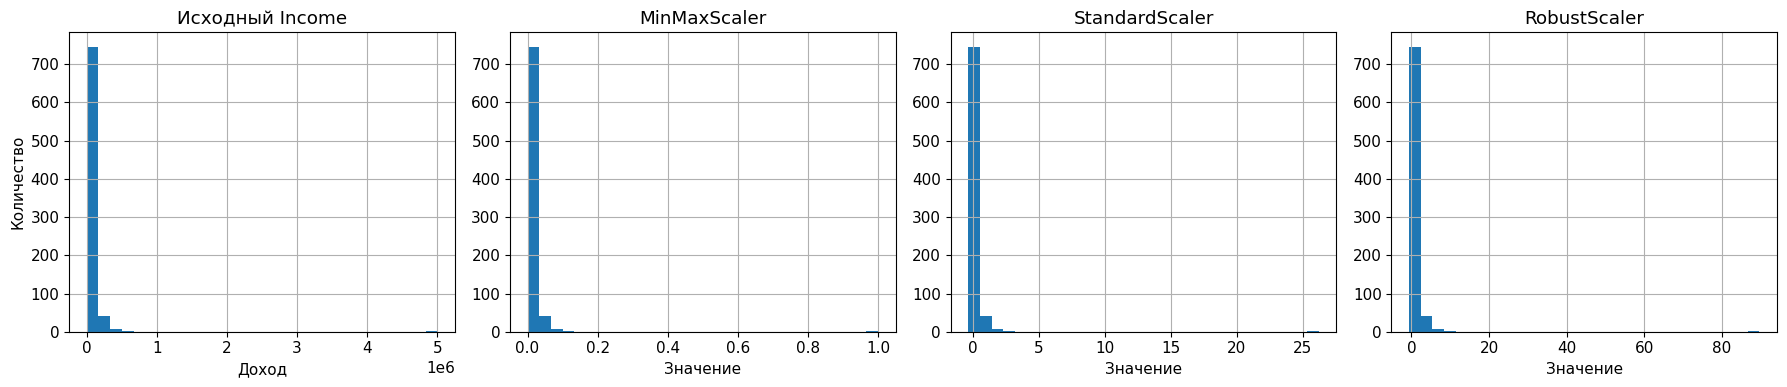

In [10]:
income = df[['Income']]

income_minmax = MinMaxScaler().fit_transform(income)
income_std = StandardScaler().fit_transform(income)
income_robust = RobustScaler().fit_transform(income)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].hist(income, bins=30)
axes[0].set_title("Исходный Income")
axes[0].set_xlabel("Доход")
axes[0].set_ylabel("Количество")

axes[1].hist(income_minmax, bins=30)
axes[1].set_title("MinMaxScaler")
axes[1].set_xlabel("Значение")

axes[2].hist(income_std, bins=30)
axes[2].set_title("StandardScaler")
axes[2].set_xlabel("Значение")

axes[3].hist(income_robust, bins=30)
axes[3].set_title("RobustScaler")
axes[3].set_xlabel("Значение")

plt.tight_layout()
plt.show()


### Задание 3.2. Выбор скейлера по признаку

Заполните таблицу для четырёх числовых признаков: скейлер и краткое (1–2 предложения) обоснование.

| Признак | Скейлер | Обоснование |
|---------|---------|-------------|
| Age | | |
| Income | | |
| Tenure | | |
| CreditScore | | |

Оформите как словари `scaler_choice` и `justification`, выведите в цикле.


In [13]:
scaler_choice = {
    'Age': 'MinMaxScaler',
    'Income': 'RobustScaler',
    'Tenure': 'MinMaxScaler',
    'CreditScore': 'MinMaxScaler'
}

justification = {
    'Age': 'Возраст распределён равномерно от 18 до 75 лет и без выбросов, подходит MinMaxScaler.',
    'Income': 'Есть огромный выброс 5 000 000, поэтому берём RobustScaler, он не боится выбросов.',
    'Tenure': 'Стаж от 1 до 60 месяцев без выбросов, MinMaxScaler переведёт его в удобный диапазон от 0 до 1.',
    'CreditScore': 'Рейтинг строго от 300 до 850 без аномалий, хорошо подойдёт MinMaxScaler.'
}

for key in scaler_choice:
    print(key, "-", scaler_choice[key])
    print("Почему:", justification[key])
    print()


Age - MinMaxScaler
Почему: Возраст распределён равномерно от 18 до 75 лет и без выбросов, подходит MinMaxScaler.

Income - RobustScaler
Почему: Есть огромный выброс 5 000 000, поэтому берём RobustScaler, он не боится выбросов.

Tenure - MinMaxScaler
Почему: Стаж от 1 до 60 месяцев без выбросов, MinMaxScaler переведёт его в удобный диапазон от 0 до 1.

CreditScore - MinMaxScaler
Почему: Рейтинг строго от 300 до 850 без аномалий, хорошо подойдёт MinMaxScaler.



## Часть 4. Кодирование категорий

### Задание 4.1. Label и One-Hot для `Gender`

Закодируйте `Gender` через `LabelEncoder` и через `pd.get_dummies`. Выведите результат.

```python
df['Gender_Label'] = LabelEncoder().fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print(df_ohe.head())
```

**Ответьте письменно:** для каких моделей Label-кодирование допустимо, а для каких — нет? Обоснуйте.

In [14]:
df['Gender_Label'] = LabelEncoder().fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print(df_ohe.head())

   Gender_F  Gender_M
0         0         1
1         0         1
2         0         1
3         1         0
4         0         1


### Задание 4.2. Ordinal-кодирование `Education`

`Education` — порядковый признак. Закодируйте его через `OrdinalEncoder` с **явно заданным** порядком: `High School < Bachelor < Master < PhD`.

```python
edu_order = [...]  # заполните сами
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])
print(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))
```

**Ответьте письменно:** что было бы, если не задать `categories` явно? Какие значения получили бы категории и насколько это соответствует реальному порядку?

In [15]:
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])

print(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))


      Education  Education_Ord
2   High School            0.0
3      Bachelor            1.0
0        Master            2.0
19          PhD            3.0


### Задание 4.3. Frequency-кодирование `City`

Закодируйте `City` через частоту встречаемости.

```python
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
print(df[['City', 'City_Freq']].drop_duplicates())
```

**Ответьте письменно:** в чём главный недостаток Frequency-кодирования? В каком сценарии этот недостаток критичен?

In [16]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
print(df[['City', 'City_Freq']].drop_duplicates())


            City  City_Freq
0            Ufa        115
1   Ekaterinburg        138
3            SPb        140
5    Novosibirsk        139
7         Moscow        135
16         Kazan        133


## Часть 5. ColumnTransformer

### Задание 5.1. Полный препроцессинг

Соберите единый `ColumnTransformer`, который:

- к `Age`, `CreditScore` применяет `StandardScaler`;
- к `Income` — `RobustScaler`;
- к `Tenure` — `MinMaxScaler`;
- к `Gender`, `City` — `OneHotEncoder(drop='first')`;
- к `Education` — `OrdinalEncoder` с тем же порядком, что в задании 4.2.

Данные на train/test разделите **до** `fit`.

```python
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'],
            errors='ignore')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[ ... ])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)
```

**Ожидаемая форма:** `(600, 7) → (600, 11)` и `(200, 7) → (200, 11)`.

Проверка по столбцам: Age и CreditScore дают 2, Income — 1, Tenure — 1, Gender — 1 (drop='first'), City — 5 (drop='first'), Education — 1. Итого 11.

**Ответьте письменно на три вопроса:**

1. Почему `fit_transform` применяется только к train, а к test — только `transform`?
2. Сколько столбцов даст `OneHotEncoder(drop='first')` на `Gender`? На `City`?
3. Что произойдёт, если в test встретится город, которого не было в train? Как это обрабатывается в sklearn по умолчанию и как можно изменить поведение?

In [18]:
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'],
            errors='ignore')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


edu_order = ['High School', 'Bachelor', 'Master', 'PhD']


preprocessor = ColumnTransformer(transformers=[
    ('std_scaler', StandardScaler(), ['Age', 'CreditScore']),
    ('robust_scaler', RobustScaler(), ['Income']),
    ('minmax_scaler', MinMaxScaler(), ['Tenure']),
    ('ohe', OneHotEncoder(drop='first'), ['Gender', 'City']),
    ('ord', OrdinalEncoder(categories=[edu_order]), ['Education'])
])


X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)


(600, 7) -> (600, 11)
(200, 7) -> (200, 11)


# Часть 6. Выборки

### Задание 6.1. Простая случайная и стратифицированная выборки

Сделайте две выборки по 100 строк:

- простую случайную (`df.sample`);
- стратифицированную по `Churn` — реализуйте функцию `stratified_sample` самостоятельно.

Подсказка: `df[strat_col].value_counts(normalize=True)` даёт доли групп, а `.sample(n=..., random_state=...)` — случайную выборку внутри группы.

```python
def stratified_sample(df, strat_col, n_total, random_state=42):
    # ваш код здесь
    ...

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)

print(f"Популяция:            {df['Churn'].mean():.3f}")
print(f"Случайная:            {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная:   {s_strat['Churn'].mean():.3f}")
```

**Ответьте письменно:**

1. Какая выборка ближе к популяции по доле `Churn`?
2. Почему при стратификации по `Churn` столбец `Churn` нельзя оставлять среди признаков `X` при обучении модели?


In [19]:
def stratified_sample(df, strat_col, n_total, random_state=42):

    proportions = df[strat_col].value_counts(normalize=True)

    samples = []

    for group_val, prop in proportions.items():
        n_group = round(n_total * prop)
        group_df = df[df[strat_col] == group_val]
        sampled_group = group_df.sample(n=n_group, random_state=random_state)
        samples.append(sampled_group)


    return pd.concat(samples)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)

print(f"Популяция:            {df['Churn'].mean():.3f}")
print(f"Случайная:            {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная:   {s_strat['Churn'].mean():.3f}")

Популяция:            0.371
Случайная:            0.320
Стратифицированная:   0.370


### Задание 6.2. Влияние размера выборки на оценку

Сгенерируйте по 100 выборок каждого размера: `n ∈ {20, 100, 500}`. Для каждой посчитайте **медиану** `Income` (медиана устойчива к единственному выбросу в 5 000 000, поэтому именно она покажет масштаб эффекта). Постройте `boxplot` для трёх серий и горизонтальную линию на уровне медианы по всей популяции.

```python
sizes = [20, 100, 500]
results = {n: [] for n in sizes}
for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())

fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--',
           label=f"Медиана в популяции = {df['Income'].median():,.0f}")
ax.set_ylabel('Медиана Income')
ax.legend()
plt.show()

for n in sizes:
    print(f"n={n}: std = {np.std(results[n]):,.0f}")
```

**Ответьте письменно:** как меняется стандартное отклонение оценки медианы с ростом `n`? Согласуется ли это с формулой стандартной ошибки `σ / √n`? Что произошло бы, если бы вместо медианы вы считали среднее?

/tmp/ipykernel_1875/1648587555.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])


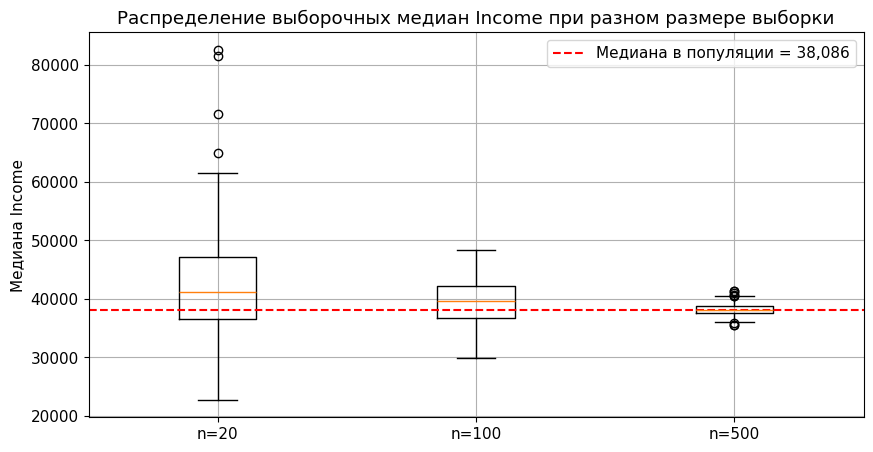

n=20: std = 10,391
n=100: std = 3,887
n=500: std = 1,138


In [20]:
sizes = [20, 100, 500]
results = {n: [] for n in sizes}
for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())

fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--',
           label=f"Медиана в популяции = {df['Income'].median():,.0f}")
ax.set_title('Распределение выборочных медиан Income при разном размере выборки')
ax.set_ylabel('Медиана Income')
ax.legend()
plt.show()

for n in sizes:
    print(f"n={n}: std = {np.std(results[n]):,.0f}")
